In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix
from scipy.stats import chi2_contingency, chi2

In [ ]:
exec_tests=pd.read_csv('sample_execution.csv')
non_exe_tests=pd.read_csv('gpt3.5_results.csv')

In [ ]:
assertion=pd.read_csv('changeAssertion_incontextLearing_results.csv')
condition=pd.read_csv('change_condition_incontextLearing_results.csv')
data_structure=pd.read_csv('changeDataSTructure_incontextLearing_results.csv')
combined_df = pd.concat([assertion, condition, data_structure], ignore_index=True)
# removed_df=pd.read_csv('37_removed_with_test_name.csv')

In [ ]:
# Extract the 'Flaky Code' values from exec_tests
exec_flaky_codes = exec_tests['Flaky Code']

# Filter Combined_df to exclude rows where 'Flaky Code' is in exec_flaky_codes
filtered_combined_df = combined_df[~combined_df['Flaky Code'].isin(exec_flaky_codes)]
#filtered_combined_df is the non-executeable tests form 131 dataset


In [ ]:
# Merge both columns to create a unique identifier for each row in both dataframes
exec_tests['identifier'] = exec_tests['class_name'] + "_" + exec_tests['test_name']
non_exe_tests['identifier'] = non_exe_tests['class_name'] + "_" + non_exe_tests['test_name']

# Use the isin() method to filter out the rows from non_exe_tests that are in exec_tests
filtered_non_exe_tests = non_exe_tests[~non_exe_tests['identifier'].isin(exec_tests['identifier'])]

# Drop the identifier column if it's no longer needed
filtered_non_exe_tests = filtered_non_exe_tests.drop(columns=['identifier'])

# filtered_non_exe_tests now contains all rows in non_exe_tests that are not in exec_tests for 181 dataset

# Logestic Regression and Chi_Square Test:

Confusion matrix:
TN:  6  instances were correctly predicted as negative (fail).
FP:  5  instances were incorrectly predicted as positive (pass).
FN:  2  instances were incorrectly predicted as negative (fail).
TP:  22  instances were correctly predicted as positive (pass).
Accuracy: 0.8
Contingency Table:
[[6, 5], [2, 22]]
Chi-Square Statistic: 6.703
Degrees of Freedom: 1
p-value: 0.010
Expected Frequencies:
[[ 2.51428571  8.48571429]
 [ 5.48571429 18.51428571]]
probability=0.950, critical=3.841, stat=6.703
Dependent (reject H0)
significance=0.050, p=0.010
Dependent (reject H0)


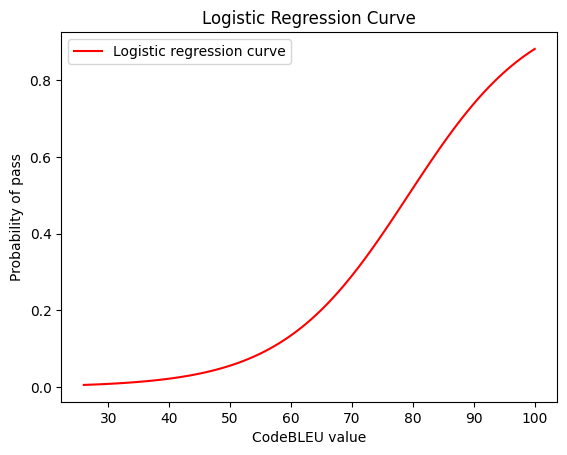

In [ ]:
# Preprocess the dataset
X = exec_tests[['CodeBLEU']].values  # Input features (Code BLEU score)
y = exec_tests['Gens_exec_result'].map({'pass': 1, 'fail': 0}).values  # Target variable (status)

# Initialize and fit the Logistic Regression model
clf = LogisticRegression(random_state=42)
clf.fit(X, y)

# Make predictions on the dataset
y_pred = clf.predict(X)

# Evaluate the predictions
confusion = confusion_matrix(y, y_pred)
print("Confusion matrix:")
print("TN: ", confusion[0, 0], " instances were correctly predicted as negative (fail).")
print("FP: ", confusion[0, 1], " instances were incorrectly predicted as positive (pass).")
print("FN: ", confusion[1, 0], " instances were incorrectly predicted as negative (fail).")
print("TP: ", confusion[1, 1], " instances were correctly predicted as positive (pass).")

# Calculate accuracy
accuracy = (confusion[0, 0] + confusion[1, 1]) / np.sum(confusion)
print("Accuracy:", accuracy)

# Construct the contingency table from the confusion matrix
table = [[confusion[0, 0], confusion[0, 1]],
         [confusion[1, 0], confusion[1, 1]]]
print("Contingency Table:")
print(table)

# Perform the Chi-Square test of independence
stat, p, dof, expected = chi2_contingency(table)
print('Chi-Square Statistic: %.3f' % stat)
print('Degrees of Freedom: %d' % dof)
print('p-value: %.3f' % p)
print('Expected Frequencies:')
print(expected)

# Interpret the test statistic with a critical value
prob = 0.95
critical = chi2.ppf(prob, dof)
print('probability=%.3f, critical=%.3f, stat=%.3f' % (prob, critical, stat))
if abs(stat) >= critical:
    print('Dependent (reject H0)')
else:
    print('Independent (fail to reject H0)')

# Interpret the p-value
alpha = 1.0 - prob
print('significance=%.3f, p=%.3f' % (alpha, p))
if p <= alpha:
    print('Dependent (reject H0)')
else:
    print('Independent (fail to reject H0)')

# Generate values for CodeBLEU to use for prediction
X_range = np.linspace(min(X), max(X), 100).reshape(-1, 1)

# Predict the probabilities of pass values using the logistic regression model
y_proba = clf.predict_proba(X_range)[:, 1]

# Plot the logistic regression curve
plt.figure()
plt.plot(X_range, y_proba, color='red', label='Logistic regression curve')

# Add labels and legend
plt.xlabel('CodeBLEU value')
plt.ylabel('Probability of pass')
plt.title('Logistic Regression Curve')
plt.legend()

# Show the plot
plt.show()


# for 181 tests:

In [ ]:
import numpy as np
import statsmodels.api as sm

X_filtered = filtered_non_exe_tests[['Code BLEU without Labels']].values  # Input features for prediction

# Add an intercept term to the input features
X_filtered_with_intercept = sm.add_constant(X_filtered)

# Get the model's coefficients (including the intercept)
coefficients = np.hstack([clf.intercept_, clf.coef_.flatten()])

# Calculate the linear predictor (logit)
logit_values = np.dot(X_filtered_with_intercept, coefficients)

# Calculate the standard errors of the logit
model_variance = np.dot(np.dot(X_filtered_with_intercept, np.linalg.inv(np.dot(X_filtered_with_intercept.T, X_filtered_with_intercept))), X_filtered_with_intercept.T)
standard_errors = np.sqrt(np.diag(model_variance))

# Calculate the confidence intervals on the logit scale
z_value = 1.96  # For a 95% confidence interval
logit_lower_bound = logit_values - z_value * standard_errors
logit_upper_bound = logit_values + z_value * standard_errors

# Transform the confidence intervals from the logit scale to the probability scale
probability_lower_bound = 1 / (1 + np.exp(-logit_lower_bound))
probability_upper_bound = 1 / (1 + np.exp(-logit_upper_bound))

# Add the confidence intervals to the dataframe
filtered_non_exe_tests['Prediction_Confidence_Lower'] = probability_lower_bound
filtered_non_exe_tests['Prediction_Confidence_Upper'] = probability_upper_bound

# Calculate the average lower and upper bound probabilities
average_lower_bound = np.mean(probability_lower_bound)
average_upper_bound = np.mean(probability_upper_bound)

print("Average Lower Bound Probability:", average_lower_bound)
print("Average Upper Bound Probability:", average_upper_bound)



Average Lower Bound Probability: 0.439686392629044
Average Upper Bound Probability: 0.5044845935964264


In [ ]:
# Assuming filtered_non_exe_tests has a column named 'Code BLEU without Labels'
X_filtered = filtered_non_exe_tests[['Code BLEU with Labels']].values  # Input features for prediction

# Add an intercept term to the input features
X_filtered_with_intercept = sm.add_constant(X_filtered)

# Get the model's coefficients (including the intercept)
coefficients = np.hstack([clf.intercept_, clf.coef_.flatten()])

# Calculate the linear predictor (logit)
logit_values = np.dot(X_filtered_with_intercept, coefficients)

# Calculate the standard errors of the logit
model_variance = np.dot(np.dot(X_filtered_with_intercept, np.linalg.inv(np.dot(X_filtered_with_intercept.T, X_filtered_with_intercept))), X_filtered_with_intercept.T)
standard_errors = np.sqrt(np.diag(model_variance))

# Calculate the confidence intervals on the logit scale
z_value = 1.96  # For a 95% confidence interval
logit_lower_bound = logit_values - z_value * standard_errors
logit_upper_bound = logit_values + z_value * standard_errors

# Transform the confidence intervals from the logit scale to the probability scale
probability_lower_bound = 1 / (1 + np.exp(-logit_lower_bound))
probability_upper_bound = 1 / (1 + np.exp(-logit_upper_bound))

# Add the confidence intervals to the dataframe
filtered_non_exe_tests['Prediction_Confidence_Lower'] = probability_lower_bound
filtered_non_exe_tests['Prediction_Confidence_Upper'] = probability_upper_bound

# Calculate the average lower and upper bound probabilities
average_lower_bound = np.mean(probability_lower_bound)
average_upper_bound = np.mean(probability_upper_bound)

print("Average Lower Bound Probability:", average_lower_bound)
print("Average Upper Bound Probability:", average_upper_bound)


Average Lower Bound Probability: 0.5061408237684888
Average Upper Bound Probability: 0.5734489357281317


# for 131 tests

In [ ]:

# Assuming filtered_non_exe_tests has a column named 'Code BLEU without Labels'
X_filtered = filtered_combined_df[['Code BLEU without Labels']].values  # Input features for prediction

# Add an intercept term to the input features
X_filtered_with_intercept = sm.add_constant(X_filtered)

# Get the model's coefficients (including the intercept)
coefficients = np.hstack([clf.intercept_, clf.coef_.flatten()])

# Calculate the linear predictor (logit)
logit_values = np.dot(X_filtered_with_intercept, coefficients)

# Calculate the standard errors of the logit
model_variance = np.dot(np.dot(X_filtered_with_intercept, np.linalg.inv(np.dot(X_filtered_with_intercept.T, X_filtered_with_intercept))), X_filtered_with_intercept.T)
standard_errors = np.sqrt(np.diag(model_variance))

# Calculate the confidence intervals on the logit scale
z_value = 1.96  # For a 95% confidence interval
logit_lower_bound = logit_values - z_value * standard_errors
logit_upper_bound = logit_values + z_value * standard_errors

# Transform the confidence intervals from the logit scale to the probability scale
probability_lower_bound = 1 / (1 + np.exp(-logit_lower_bound))
probability_upper_bound = 1 / (1 + np.exp(-logit_upper_bound))

# Add the confidence intervals to the dataframe
filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound

# Calculate the average lower and upper bound probabilities
average_lower_bound = np.mean(probability_lower_bound)
average_upper_bound = np.mean(probability_upper_bound)

print("Average Lower Bound Probability:", average_lower_bound)
print("Average Upper Bound Probability:", average_upper_bound)



Average Lower Bound Probability: 0.43706504478342323
Average Upper Bound Probability: 0.5182951668195044


<ipython-input-9-39507cb910b8>:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
<ipython-input-9-39507cb910b8>:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound


In [ ]:
# Assuming filtered_non_exe_tests has a column named 'Code BLEU without Labels'
X_filtered = filtered_combined_df[['Code BLEU with Labels']].values  # Input features for prediction

# Add an intercept term to the input features
X_filtered_with_intercept = sm.add_constant(X_filtered)

# Get the model's coefficients (including the intercept)
coefficients = np.hstack([clf.intercept_, clf.coef_.flatten()])

# Calculate the linear predictor (logit)
logit_values = np.dot(X_filtered_with_intercept, coefficients)

# Calculate the standard errors of the logit
model_variance = np.dot(np.dot(X_filtered_with_intercept, np.linalg.inv(np.dot(X_filtered_with_intercept.T, X_filtered_with_intercept))), X_filtered_with_intercept.T)
standard_errors = np.sqrt(np.diag(model_variance))

# Calculate the confidence intervals on the logit scale
z_value = 1.96  # For a 95% confidence interval
logit_lower_bound = logit_values - z_value * standard_errors
logit_upper_bound = logit_values + z_value * standard_errors

# Transform the confidence intervals from the logit scale to the probability scale
probability_lower_bound = 1 / (1 + np.exp(-logit_lower_bound))
probability_upper_bound = 1 / (1 + np.exp(-logit_upper_bound))

# Add the confidence intervals to the dataframe
filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound

# Calculate the average lower and upper bound probabilities
average_lower_bound = np.mean(probability_lower_bound)
average_upper_bound = np.mean(probability_upper_bound)

print("Average Lower Bound Probability:", average_lower_bound)
print("Average Upper Bound Probability:", average_upper_bound)



Average Lower Bound Probability: 0.496043428269392
Average Upper Bound Probability: 0.5791461598755228


<ipython-input-10-7277f71778e9>:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
<ipython-input-10-7277f71778e9>:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound


In [ ]:
# Assuming filtered_non_exe_tests has a column named 'Code BLEU without Labels'
X_filtered = filtered_combined_df[['Code BLEU with FSP']].values  # Input features for prediction

# Add an intercept term to the input features
X_filtered_with_intercept = sm.add_constant(X_filtered)

# Get the model's coefficients (including the intercept)
coefficients = np.hstack([clf.intercept_, clf.coef_.flatten()])

# Calculate the linear predictor (logit)
logit_values = np.dot(X_filtered_with_intercept, coefficients)

# Calculate the standard errors of the logit
model_variance = np.dot(np.dot(X_filtered_with_intercept, np.linalg.inv(np.dot(X_filtered_with_intercept.T, X_filtered_with_intercept))), X_filtered_with_intercept.T)
standard_errors = np.sqrt(np.diag(model_variance))

# Calculate the confidence intervals on the logit scale
z_value = 1.96  # For a 95% confidence interval
logit_lower_bound = logit_values - z_value * standard_errors
logit_upper_bound = logit_values + z_value * standard_errors

# Transform the confidence intervals from the logit scale to the probability scale
probability_lower_bound = 1 / (1 + np.exp(-logit_lower_bound))
probability_upper_bound = 1 / (1 + np.exp(-logit_upper_bound))

# Add the confidence intervals to the dataframe
filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound

# Calculate the average lower and upper bound probabilities
average_lower_bound = np.mean(probability_lower_bound)
average_upper_bound = np.mean(probability_upper_bound)

print("Average Lower Bound Probability:", average_lower_bound)
print("Average Upper Bound Probability:", average_upper_bound)


Average Lower Bound Probability: 0.5272948167636032
Average Upper Bound Probability: 0.6034552821618712


<ipython-input-11-639a8b15881e>:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Lower'] = probability_lower_bound
<ipython-input-11-639a8b15881e>:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_combined_df['Prediction_Confidence_Upper'] = probability_upper_bound
